In [1]:
import sys

print(sys.version)

3.14.10 (main, Nov 11 2026, 00:18:44) [Clang 23.1.3 ]


# Common Boggle Words

Which words turn up most often on a Boggle board, and which of them are worth knowing?

This notebook answers the first question by sampling boards. The second needs people, not simulation. [Common on the board, rare in English](https://attobop.net/posts/boggle-words/) separates what can be simulated (how often a word appears, how many points it offers) from what cannot (whether a player knows the word, notices it in time, and is the only one to write it down). The counts below reproduce that post's exactly: the same cubes, the same dictionary and the same random seed.

## The rules

Classic Boggle has 16 cubes with a letter on each face, shaken into a 4 by 4 grid. A word is a path through neighboring cubes (horizontally, vertically or diagonally) that uses no cube twice, though a letter may repeat on different cubes. A word needs at least three letters, and the `Qu` face counts as two letters on one cube. Words score by length (Hasbro's [instructions](https://www.hasbro.com/common/instruct/boggle.pdf)):

| letters | 3 or 4 | 5 | 6 | 7 | 8 or more |
|---|---|---|---|---|---|
| points | 1 | 2 | 3 | 5 | 11 |

With several players, a word that two or more players find is crossed off every list.

## Too many boards to count

If the cubes are told apart, there are $16!$ ways to place them and $6^{16}$ ways to choose their faces:

In [2]:
from math import factorial

f"{factorial(16) * 6**16:.2e}"

'5.90e+25'

Duplicate letters and the symmetries of the square make the number of different-looking boards smaller, but not small enough. Even at a hundred million boards a second, checking them all would take a while:

In [3]:
BOARDS = 5.9e25  # 16! * 6**16 position-and-face outcomes
RATE = 1e8  # boards per second
print(f"about {BOARDS / RATE / (365.25 * 24 * 3600):.1g} years")

about 2e+10 years


Great Scott! So we sample boards instead.

## Simulating Boggle

The code for boards and word search is in `boggle.py`, next to this notebook, so the tests can import it too. These are the 16 cubes it uses. The rules do not list cube faces, and editions differ, so every probability below describes this set of cubes.

In [4]:
from boggle import CUBES

CUBES

[('a', 'a', 'e', 'e', 'g', 'n'),
 ('a', 'b', 'b', 'j', 'o', 'o'),
 ('a', 'c', 'h', 'o', 'p', 's'),
 ('a', 'f', 'f', 'k', 'p', 's'),
 ('a', 'o', 'o', 't', 't', 'w'),
 ('c', 'i', 'm', 'o', 't', 'u'),
 ('d', 'e', 'i', 'l', 'r', 'x'),
 ('d', 'e', 'l', 'r', 'v', 'y'),
 ('d', 'i', 's', 't', 't', 'y'),
 ('e', 'e', 'g', 'h', 'n', 'w'),
 ('e', 'e', 'i', 'n', 's', 'u'),
 ('e', 'h', 'r', 't', 'v', 'w'),
 ('e', 'i', 'o', 's', 's', 't'),
 ('e', 'l', 'r', 't', 't', 'y'),
 ('h', 'i', 'm', 'n', 'qu', 'u'),
 ('h', 'l', 'n', 'n', 'r', 'z')]

To shake the board, `rand_board` puts the cubes in a random order and shows a random face of each. Every random choice comes from a seeded `random.Random`, so each number here can be reproduced.

In [5]:
import random

from boggle import rand_board

board = rand_board(random.Random(0))
board

[['i', 'h', 'r', 'e'],
 ['t', 'y', 'v', 'l'],
 ['r', 'a', 's', 'e'],
 ['o', 'm', 'n', 's']]

To find the words on a board, we follow paths from every cube to its unused neighbors. Looking each partial path up in a set of words would waste time on paths that cannot become words, so the dictionary goes into a trie, a tree of letters ([an elegant version](http://stackoverflow.com/a/11016430)), and a path stops as soon as its letters are not a prefix of any word.

In [6]:
import json

from boggle import make_trie

print(json.dumps(make_trie(['apply', 'apple', 'apt']), indent=2))

{
  "a": {
    "p": {
      "p": {
        "l": {
          "y": {
            "null": null
          },
          "e": {
            "null": null
          }
        }
      },
      "t": {
        "null": null
      }
    }
  }
}


The `Qu` face needs care. The trie has a `q` branch followed by a `u` branch, but no `qu` branch, so looking up the whole face as one key would silently miss every Q word. `get_words` follows each letter printed on a face before moving to the next cube; the path still uses one cube.

The dictionary is ENABLE, a permissive word-game list rather than an official tournament dictionary. `load_words` checks the file's SHA-256 digest, so a changed word list cannot quietly change the results. Here are the words on the board above:

In [7]:
from boggle import get_words, load_words, points

words = load_words('enable1.txt', sha256='a392640f14602fcbb36779eb6671d170260c06d43f41c16383e7f0e35b221b4a')
trie = make_trie(w for w in words if len(w) >= 3)
found = sorted(get_words(board, trie), key=lambda w: (-len(w), w))
print(len(words), 'dictionary words;', len(found), 'on this board, worth', sum(map(points, found)), 'points:')
print(' '.join(found))

172820 dictionary words; 183 on this board, worth 284 points:
traveler raveler travels enamor manses martyr mavens morass morays navels ravels ravens revels romans selvas senary smarty tassel travel traves amort anele avens elver elves essay evens every lever manes manse masse maven moans moras moray navel naves never oases oaves rases ravel raven raver raves revel rhyta roams roans roman sanes satyr saver saves selva sensa sever smart snath tansy tasse trams trans trass trave trays vanes vases anes arms arty aver aves else even ever eves lens less leva levy mane mans mart mass math mays moan moas moat mora mort nary nave navy nays ness neve oath rams rase rath rave rays revs roam roan roms ryas sane sans sati save sels tams tans taro tass tavs tram tray tyre tyro vane vans vary vase vena very yams ane arm art ass ave ays els ens ess eve hit lev man mar mas mat may moa mor nam nay oar oat oms ora ort ram ran ras rat ray rev rom rya sat say sel sen tam tan tao tar tas tav thy try van va

## How many boards?

Fix one word $w$. A random board either contains it or not, so each board is a yes-or-no trial with unknown probability $p_w$, the word's **board probability**. With $n$ independent boards, the share of boards containing $w$, $\hat p_w$, estimates $p_w$, and Hoeffding's inequality bounds its error:

$$P\left(|\hat p_w - p_w| > \epsilon\right) \le 2 e^{-2n\epsilon^2}.$$

To make the right side at most $\delta$, it is enough that

$$n \ge \frac{\log(2/\delta)}{2\epsilon^2}.$$

With $\epsilon = 0.01$ and $\delta = 0.1$ that is 14,979 boards. But that is a guarantee for *one* word chosen before sampling. For $K$ words fixed in advance, a union bound replaces $\delta$ by $\delta / K$. A top-20 list is chosen *after* looking at the counts, so neither bound covers it; that needs a held-out sample. The tables below give each word an ordinary 95% Wilson interval instead, and do not claim that near-tied words are in the right order.

In [8]:
from boggle import hoeffding_boards

{k: hoeffding_boards(0.01, 0.1, words=k) for k in (1, 20, 1000)}

{1: 14979, 20: 29958, 1000: 49518}

## What appears

We draw 15,000 boards one after another from a single generator seeded with 20161126, as the post does, and count how many boards contain each word of at least three letters.

In [9]:
from tabulate import tabulate

from boggle import count_words, sample_boards, wilson

NBOARDS, SEED = 15_000, 20161126
boards = sample_boards(NBOARDS, SEED)
counts = count_words(boards, trie, min_len=3)


def common(min_len=3, top=15):
    """The most common words with at least min_len letters, with 95% Wilson intervals."""
    rows = sorted(((-c, w) for w, c in counts.items() if len(w) >= min_len))[:top]
    for rank, (neg, w) in enumerate(rows, start=1):
        low, high = wilson(-neg, NBOARDS)
        yield rank, w, -neg, f'{-neg / NBOARDS:.2%}', f'{low:.2%} to {high:.2%}'


print(tabulate(common(), headers=['rank', 'word', 'boards', 'probability', '95% interval']))

  rank  word      boards  probability    95% interval
------  ------  --------  -------------  ----------------
     1  toe         2866  19.11%         18.49% to 19.74%
     2  tee         2721  18.14%         17.53% to 18.76%
     3  tea         2691  17.94%         17.33% to 18.56%
     4  net         2682  17.88%         17.28% to 18.50%
     5  ten         2682  17.88%         17.28% to 18.50%
     6  ate         2659  17.73%         17.12% to 18.35%
     7  eta         2659  17.73%         17.12% to 18.35%
     8  set         2560  17.07%         16.47% to 17.68%
     9  tie         2525  16.83%         16.24% to 17.44%
    10  eat         2517  16.78%         16.19% to 17.39%
    11  tae         2517  16.78%         16.19% to 17.39%
    12  het         2355  15.70%         15.13% to 16.29%
    13  eth         2299  15.33%         14.76% to 15.91%
    14  ret         2239  14.93%         14.37% to 15.51%
    15  the         2193  14.62%         14.06% to 15.19%


These are the counts in the post's table, to the board:

In [10]:
assert [counts[w] for w in ('toe', 'tee', 'tea', 'net', 'ten')] == [2866, 2721, 2691, 2682, 2682]

Three-letter words dominate. With at least four letters the list changes, but stays tightly bunched:

In [11]:
print(tabulate(common(min_len=4), headers=['rank', 'word', 'boards', 'probability', '95% interval']))

  rank  word      boards  probability    95% interval
------  ------  --------  -------------  --------------
     1  teen         922  6.15%          5.77% to 6.54%
     2  tent         917  6.11%          5.74% to 6.51%
     3  tees         911  6.07%          5.70% to 6.47%
     4  note         868  5.79%          5.42% to 6.17%
     5  teat         867  5.78%          5.42% to 6.16%
     6  toea         851  5.67%          5.31% to 6.06%
     7  toes         843  5.62%          5.26% to 6.00%
     8  tone         825  5.50%          5.15% to 5.88%
     9  nets         821  5.47%          5.12% to 5.85%
    10  test         817  5.45%          5.09% to 5.82%
    11  rote         797  5.31%          4.97% to 5.68%
    12  tote         797  5.31%          4.97% to 5.68%
    13  stet         794  5.29%          4.95% to 5.66%
    14  tets         794  5.29%          4.95% to 5.66%
    15  tens         790  5.27%          4.92% to 5.64%


For comparison, Dan Vanderkam's [sample of 50,000 boards](https://www.danvk.org/wp/2007-02-11/some-boggle-statistics/index.html) (2007) puts toe at 19.3% and tee at 19.1%, and the most common four-letter words at teen 6.7%, tees 6.6% and tent 6.0%. Those are the same words, with frequencies within about one percentage point of these. His cube set and dictionary may differ from the ones here.

## Points on offer

A common word is not necessarily a valuable one. For one player, a first measure is the **solo opportunity** of a word,

$$O(w) = s(w)\,p_w,$$

the official points $s(w)$ times the board probability: the points per board the word makes available to a player who finds everything. Summed over all words, it is the expected total score on offer per board. We compute that total two ways, summing over words and averaging over boards, and check that they agree. (Keeping each board's word list also serves the sections below.)

In [12]:
import numpy as np

opportunity = {w: points(w) * c / NBOARDS for w, c in counts.items()}
board_words = [list(get_words(b, trie)) for b in boards]
per_word = sum(opportunity.values())
per_board = np.mean([sum(map(points, ws)) for ws in board_words])
assert abs(per_word - per_board) < 1e-9
print(f'{per_word:.2f} points on offer per board, {np.mean([len(ws) for ws in board_words]):.2f} words')

rows = sorted(opportunity.items(), key=lambda item: -item[1])[:12]
print(tabulate([(w, points(w), f'{counts[w] / NBOARDS:.2%}', f'{o:.4f}') for w, o in rows],
               headers=['word', 'points', 'probability', 'solo opportunity']))

140.02 points on offer per board, 97.83 words
word      points  probability      solo opportunity
------  --------  -------------  ------------------
toe            1  19.11%                     0.1911
tee            1  18.14%                     0.1814
tea            1  17.94%                     0.1794
ten            1  17.88%                     0.1788
net            1  17.88%                     0.1788
ate            1  17.73%                     0.1773
eta            1  17.73%                     0.1773
set            1  17.07%                     0.1707
tie            1  16.83%                     0.1683
eat            1  16.78%                     0.1678
tae            1  16.78%                     0.1678
het            1  15.70%                     0.157


Dan Vanderkam's sample of five million boards gives 140.97 points and 98.53 words per board, close to the figures here. At one point each, three- and four-letter words supply most of the opportunity, so the list above is the most-common list again.

## Common on the board, rare in English

An earlier version of this notebook ranked words with a TF-IDF-like score: board frequency times a decreasing function of a word's count in a text corpus, giving words missing from the corpus the smallest count found. The post explains why that was the wrong tool. There are no documents, so "TF-IDF" is a misnomer. A word can be missing from a corpus because of spelling, tokenization or coverage, not only because it is obscure. And a word's corpus frequency is not whether players know it, which is not whether they notice it on the board.

So the two measurements stay separate. Below, English frequency comes from `wordfreq` 3.1.1 as a Zipf value (about 1 for rare words, 7 for the most common). Words below its cutoff are marked unlisted, rather than given a number.

In [13]:
from wordfreq import zipf_frequency

eight = ('toea', 'teat', 'stet', 'nett', 'seta', 'rete', 'tret', 'sett')
print(tabulate([(w, f'{counts[w] / NBOARDS:.2%}', f'{opportunity[w]:.4f}',
                 f'{zipf_frequency(w, "en"):.2f}' if zipf_frequency(w, 'en') else 'unlisted')
                for w in eight], headers=['word', 'board probability', 'solo opportunity', 'Zipf']))

word    board probability      solo opportunity  Zipf
------  -------------------  ------------------  --------
toea    5.67%                            0.0567  unlisted
teat    5.78%                            0.0578  2.50
stet    5.29%                            0.0529  1.83
nett    5.23%                            0.0523  2.41
seta    5.10%                            0.051   2.28
rete    4.89%                            0.0489  2.04
tret    4.81%                            0.0481  1.63
sett    4.67%                            0.0467  2.27


The plot puts every word that appears on at least 15 boards on both axes. The highlighted words are not beaten on both measures at once by any other word: more opportunity *and* rarer in English. To avoid reading noise as signal, that frontier is computed separately in each half of the sample, and only words on both halves' frontiers are highlighted.

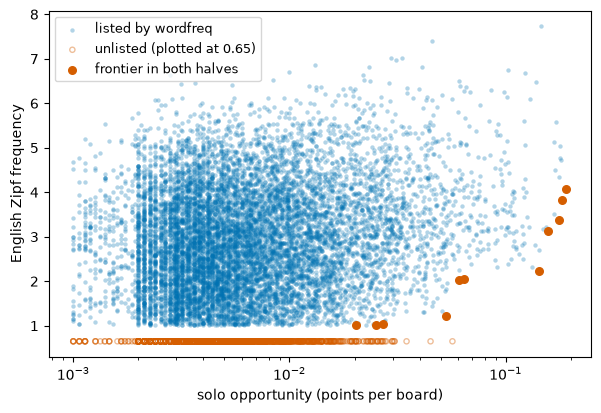

11 stable frontier words: toe tee eta het oes teg wae tets neats leets teethe


In [14]:
import matplotlib.pyplot as plt

half = NBOARDS // 2
first, second = count_words(boards[:half], trie), count_words(boards[half:], trie)


def frontier(sample):
    """Words that no other word beats on both solo opportunity and rarity."""
    rows = [(points(w) * c / half, zipf_frequency(w, 'en'), w) for w, c in sample.items() if c >= 8]
    rows = [r for r in rows if r[1] > 0 and r[0] >= 0.003]
    best, out = float('inf'), set()
    for _, z, w in sorted(rows, key=lambda r: (-r[0], r[1])):
        if z < best:
            out.add(w)
            best = z
    return out


stable = frontier(first) & frontier(second)
shown = [w for w, c in counts.items() if c >= 15]
zipf = {w: zipf_frequency(w, 'en') for w in shown}
fig, ax = plt.subplots(figsize=(7, 4.5))
listed = [w for w in shown if zipf[w] > 0]
unlisted = [w for w in shown if zipf[w] == 0]
ax.scatter([opportunity[w] for w in listed], [zipf[w] for w in listed], s=10, alpha=0.3,
           color='#0072B2', linewidths=0, label='listed by wordfreq')
ax.scatter([opportunity[w] for w in unlisted], [0.65] * len(unlisted), s=14, alpha=0.4,
           facecolors='none', edgecolors='#D55E00', label='unlisted (plotted at 0.65)')
ax.scatter([opportunity[w] for w in stable], [zipf[w] for w in stable], s=30,
           color='#D55E00', label='frontier in both halves')
ax.set_xscale('log')
ax.set_xlabel('solo opportunity (points per board)')
ax.set_ylabel('English Zipf frequency')
ax.legend(loc='upper left', fontsize=9)
plt.show()
print(len(stable), 'stable frontier words:', ' '.join(sorted(stable, key=lambda w: -opportunity[w])))

These are words to *test*, not to memorize. Whether learning _toea_ earns points depends on whether a player then finds it in time, and on whether opponents find it too; the post sets out the experiment that would measure that.

## How many words on a board?

The number of words varies a lot from board to board. Here is its distribution over all the sampled boards:

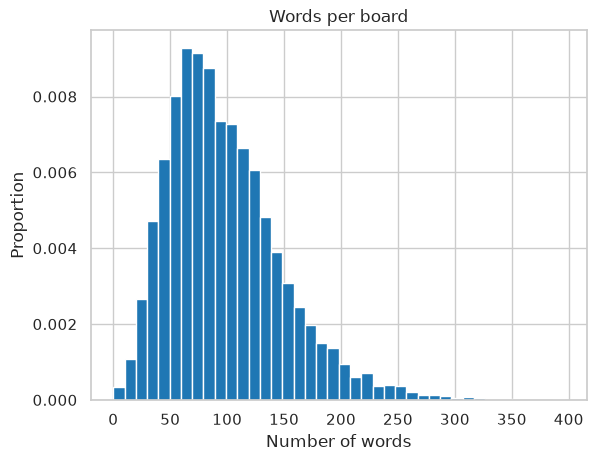

mean 97.8, median 90, fewest 0, most 396


In [15]:
import seaborn

seaborn.set_context('notebook')
seaborn.set_style('whitegrid')

num_words = [len(ws) for ws in board_words]
plt.hist(num_words, bins=40, density=True)
plt.title('Words per board')
plt.xlabel('Number of words')
plt.ylabel('Proportion')
plt.show()
print(f'mean {np.mean(num_words):.1f}, median {np.median(num_words):.0f}, fewest {min(num_words)}, most {max(num_words)}')

## Best proportion of vowels

A friend once said that the best Boggle boards are about 40% vowels, where best means the most words. We can check: group the boards by their number of vowels, and average the number of words of four or more letters in each group, with a 95% interval.

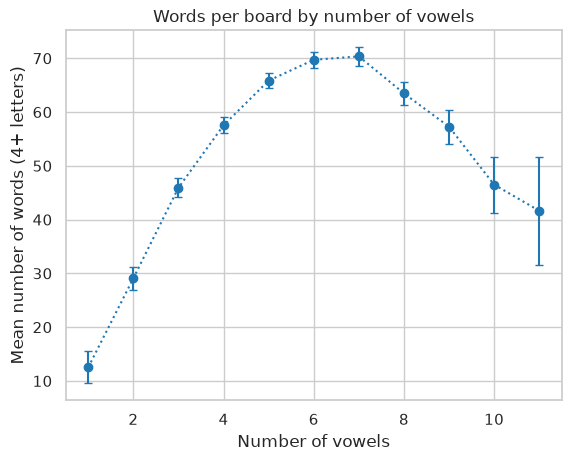

{0: 6, 1: 89, 2: 455, 3: 1285, 4: 2458, 5: 3281, 6: 3267, 7: 2289, 8: 1207, 9: 466, 10: 149, 11: 37, 12: 8, 13: 3} (boards with that many vowels)
{1: 12.6, 2: 29.1, 3: 45.9, 4: 57.6, 5: 65.8, 6: 69.7, 7: 70.4, 8: 63.5, 9: 57.3, 10: 46.5, 11: 41.6} (mean words; groups of fewer than 30 boards left out)


In [16]:
from collections import defaultdict

vowels = set('aeiou')  # for simplicity, these are the only vowels
words_by_vowels = defaultdict(list)
for b, ws in zip(boards, board_words, strict=True):
    n_vowels = sum(face[0] in vowels for row in b for face in row)
    words_by_vowels[n_vowels].append(sum(len(w) >= 4 for w in ws))

x = [v for v in sorted(words_by_vowels) if len(words_by_vowels[v]) >= 30]
means = [np.mean(words_by_vowels[v]) for v in x]
halves = [1.96 * np.std(words_by_vowels[v], ddof=1) / np.sqrt(len(words_by_vowels[v])) for v in x]
plt.errorbar(x, means, yerr=halves, fmt='o:', capsize=3)
plt.title('Words per board by number of vowels')
plt.xlabel('Number of vowels')
plt.ylabel('Mean number of words (4+ letters)')
plt.show()
print({v: len(words_by_vowels[v]) for v in sorted(words_by_vowels)}, '(boards with that many vowels)')
print({v: round(float(m), 1) for v, m in zip(x, means, strict=True)}, '(mean words; groups of fewer than 30 boards left out)')

The peak is at six and seven vowels, 37.5% and 44% of the board, and their intervals overlap; 40% sits between them, so the remark holds up. Boards with very few or very many vowels are rare, which is why the intervals widen at the ends.

## Words never seen

The sample found many words, but not every word that can appear. How much is missing? Count each appearance of a word on a board as one observation. Turing and Good estimated the chance that the next observation is a new word by a simple share: the share of observations that are words seen exactly once. The post [You've seen 100 species. How many exist?](https://attobop.net/posts/unseen-species/) explains why that share is a sound estimate, and why it says nothing by itself about *how many* unseen words there are.

In [17]:
seen_once = sum(c == 1 for c in counts.values())
appearances = sum(counts.values())
playable = sum(len(w) >= 3 for w in words)
print(f'{len(counts):,} different words seen, of {playable:,} dictionary words with 3+ letters')
print(f'{seen_once:,} seen on exactly one board, out of {appearances:,} appearances: '
      f'missing mass about {seen_once / appearances:.4%}')

41,171 different words seen, of 172,724 dictionary words with 3+ letters
11,018 seen on exactly one board, out of 1,467,424 appearances: missing mass about 0.7508%


So about one word appearance in 130 on a fresh board would be a word this sample never saw. Yet more than a quarter of the words that were seen turned up on only one board: the tail is long. The 131,553 dictionary words never seen are either rare on boards or impossible with these cubes, and the sample alone cannot say which.

## Questions left open

- **Findability and cancellation.** Board probability and solo opportunity can be simulated. Whether a player finds a word, and whether an opponent finds it too, needs an experiment with people; the post describes one.
- **Other editions.** Big Boggle (5 by 5) and Super Big Boggle (6 by 6) have different cubes and minimum lengths. Their cube sets would need transcribing from the physical games first.
- **Exact probabilities.** For a single short word, the board probability could be computed exactly, not sampled, by counting the placements of the cubes that can spell it.